# 03 · Spend inference compute

When does another sample or a verifier pay for itself?

Run greedy decoding, fixed-size sampling and verifier-guided selection on the same checkable cases. Include a matched-budget arm. Select the budget on development cases and keep the release split closed.

**Measures** — Strict outcome pass rate, extra tokens, wall time and cost proxy per additional correct decision.

**Evidence** — Quality versus compute curve and a proposed inference budget.

**Runtime** — T4. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 3

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


# Lab 03 · Spend inference compute

[Read the lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/1-measure-the-model/03-spend-inference-compute).

A facilities operator has time to inspect exactly two assets before shift
change. Given a short work list, select the feasible pair with the highest
combined priority. We compare greedy decoding, plurality voting, and
verifier-guided selection. The sampled arms use the same generated
candidates at each sample count, so a difference comes from selection.

Each shortlist contains development asset identifiers from the operator's
yard and invented priorities and durations. Change only the shift time left,
then predict which pair should win. We can calculate the optimum exactly
and check whether model compute is justified for this workload.

The full lab calls the pinned model on a T4. The local check uses constructed
candidate lists and records no model timings or model results.

In [6]:
from collections import Counter
from itertools import combinations
from statistics import median
from time import perf_counter

TOKEN_LIMIT = 32
SAMPLING_TEMPERATURE = 0.65
TOP_P = 0.9
SAMPLE_COUNTS = (1, 2, 4)
MINIMUM_MODEL_PASS_RATE = 0.90
ACTIVE_SPLIT = "dev"
BOOTSTRAP_DRAWS = 1500
run_started = perf_counter()

dev_assets = sorted(assets(ACTIVE_SPLIT), key=lambda row: row["asset"] != "F-250")
work_orders = []
for index, anchor in enumerate(dev_assets):
    neighbours = [row for row in dev_assets
                  if row["tenant"] == anchor["tenant"] and row["asset"] != anchor["asset"]]
    pivot = index % len(neighbours)
    shortlist = [anchor, *(neighbours[pivot:] + neighbours[:pivot])[:4]]
    # Make the top two priorities slower than any pair that uses a reserve asset.
    options = [
        {"asset": row["asset"], "minutes": minutes + (index + offset) % 3,
         "priority": priority + (index * offset) % 3}
        for offset, (row, minutes, priority) in enumerate(zip(
            shortlist, (15, 13, 9, 7, 6), (14, 10, 6, 4, 2),
        ))
    ]
    cutoff = options[0]["minutes"] + options[1]["minutes"]
    for variant, budget in (("tight", cutoff - 1), ("loose", cutoff)):
        work_orders.append({
            "case_id": f"{anchor['family']}-{variant}",
            "family": anchor["family"], "slice": anchor["slice"], "tenant": anchor["tenant"],
            "seed": 4170 + index, "budget_variant": variant, "budget_minutes": budget,
            "options": options,
        })

assert len({row["case_id"] for row in work_orders}) == len(work_orders)
assert {row["slice"] for row in work_orders} == set(SLICES)
print("Work orders by benchmark slice:", dict(Counter(row["slice"] for row in work_orders)))
print("Opening work orders, same shortlist with one extra minute:", work_orders[:2])

Work orders by benchmark slice: {'follow_up': 4, 'manual': 4, 'numeric': 4, 'multi_source': 4, 'ambiguity': 4, 'boundary': 4}
Opening work orders, same shortlist with one extra minute: [{'case_id': 'F250-tight', 'family': 'F250', 'slice': 'follow_up', 'tenant': 'north-yard', 'seed': 4170, 'budget_variant': 'tight', 'budget_minutes': 28, 'options': [{'asset': 'F-250', 'minutes': 15, 'priority': 14}, {'asset': 'V-200', 'minutes': 14, 'priority': 10}, {'asset': 'P-210', 'minutes': 11, 'priority': 6}, {'asset': 'F-220', 'minutes': 7, 'priority': 4}, {'asset': 'V-230', 'minutes': 7, 'priority': 2}]}, {'case_id': 'F250-loose', 'family': 'F250', 'slice': 'follow_up', 'tenant': 'north-yard', 'seed': 4170, 'budget_variant': 'loose', 'budget_minutes': 29, 'options': [{'asset': 'F-250', 'minutes': 15, 'priority': 14}, {'asset': 'V-200', 'minutes': 14, 'priority': 10}, {'asset': 'P-210', 'minutes': 11, 'priority': 6}, {'asset': 'F-220', 'minutes': 7, 'priority': 4}, {'asset': 'V-230', 'minutes': 7

## Keep selection and grading independent

The verifier can tell whether a generated pair complies with the work
order and sum its priority. It can only choose among proposed pairs.
The reference solver enumerates every pair, so it can independently
tell whether a feasible proposal reached the true optimum. Order in the
returned JSON array is immaterial and we allow either pair if optimal
scores tie. Invalid responses contribute to the failure count.

Plurality selects the most frequent parsed pair regardless of feasibility.
Unparseable outputs share one empty ballot. A tie goes to the earliest tied
ballot. The verifier selects the feasible proposal with the highest priority
or returns no pair. Both selectors receive every candidate in the same batch.

In [7]:
def parse_pair(raw):
    try:
        items = json.loads(raw.strip())
    except (AttributeError, ValueError):
        return ()
    if not isinstance(items, list) or len(items) != 2 or not all(isinstance(item, str) for item in items):
        return ()
    return tuple(sorted(items))


def verify_pair(order, pair):
    options = {row["asset"]: row for row in order["options"]}
    if len(pair) != 2:
        return {"feasible": False, "priority": None, "minutes": None, "check": "no_pair"}
    if len(set(pair)) != 2 or not set(pair) <= options.keys():
        return {"feasible": False, "priority": None, "minutes": None, "check": "invalid_assets"}
    minutes = sum(options[asset]["minutes"] for asset in pair)
    feasible = minutes <= order["budget_minutes"]
    return {
        "feasible": feasible,
        "priority": sum(options[asset]["priority"] for asset in pair),
        "minutes": minutes,
        "check": "feasible" if feasible else "over_budget",
    }


def exact_pair(order):
    options = list(order["options"])
    eligible = [
        (sum(row["priority"] for row in items), tuple(sorted(row["asset"] for row in items)))
        for items in combinations(options, 2)
        if sum(row["minutes"] for row in items) <= order["budget_minutes"]
    ]
    return max(eligible)


def choose_pair(order, candidates, policy):
    if policy == "greedy":
        return candidates[0]
    if policy == "plurality":
        return Counter(candidates).most_common(1)[0][0]

    def candidate_key(pair):
        check = verify_pair(order, pair)
        return check["feasible"], check["priority"] if check["feasible"] else -1

    candidate = max(candidates, key=candidate_key)
    return candidate if verify_pair(order, candidate)["feasible"] else ()


def grade_pair(order, pair, optimum):
    check = verify_pair(order, pair)
    outcome = check["check"]
    if check["feasible"]:
        outcome = "optimal" if check["priority"] == optimum else "suboptimal"
    return {**check, "outcome": outcome, "strict_pass": outcome == "optimal"}


def build_prompt(order):
    table = "\n".join(f"{row['asset']} | {row['minutes']} | {row['priority']}"
                      for row in order["options"])
    return (
        "Choose exactly two different assets to inspect. Their total duration must be at or "
        "below the available minutes. Maximise the sum of their priorities. Reply only with "
        'a JSON array of two asset identifier strings, for example ["A-1","B-2"].\n'
        f"Available minutes: {order['budget_minutes']}\n"
        f"Asset | Duration in minutes | Priority\n{table}"
    )


example = work_orders[0]
best_priority, best_pair = exact_pair(example)
assert verify_pair(example, best_pair)["priority"] == best_priority
for tight, loose in zip(work_orders[::2], work_orders[1::2]):
    assert tight["options"] == loose["options"] and tight["family"] == loose["family"]
    assert exact_pair(tight)[0] < exact_pair(loose)[0]
boundary_candidates = [("unknown-a", "unknown-b"), ("unknown-a", "unknown-b"), best_pair]
assert not verify_pair(example, choose_pair(example, boundary_candidates, "plurality"))["feasible"]
assert choose_pair(example, boundary_candidates, "verified") == best_pair
print("Exact pair for first work order:", best_pair, "combined priority", best_priority)
print("Constructed boundary example: plurality chose the unavailable pair. Verification rescued it.")

Exact pair for first work order: ('F-250', 'P-210') combined priority 20
Constructed boundary example: plurality chose the unavailable pair. Verification rescued it.


## Measure the token and wall-time budget

Measure direct generation with CUDA synchronised at both boundaries.
Count prompt tokens for each candidate because each sample conditions on
the prompt. Count generated tokens through the first EOS rather than
counting padding or retokenising the decoded text. This token total is a
compute proxy. A batched sampler can share execution work, and much of
the total wall time can come from prefill and kernel launches.

For the first and warm timing comparison we use the same work order,
greedy policy, and maximum output. The scored development run starts
after that profiling warm-up. Both sample selectors inherit the same
real generation wall time. Their own selection time is measured separately.

In [8]:
generation_rows = []
case_rows = []
first_and_warm = []
load_ms = None

if not COURSE_SMOKE:
    import torch

    started = perf_counter()
    tokenizer, text_model = load_text()
    sync()
    load_ms = (perf_counter() - started) * 1000


def generate_pairs(order, samples):
    sync()
    on_cuda = text_model.device.type == "cuda"
    idle_bytes = None
    if on_cuda:
        idle_bytes = torch.cuda.memory_allocated()
        torch.cuda.reset_peak_memory_stats()

    started = perf_counter()
    torch.manual_seed(order["seed"])
    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": build_prompt(order)}], tokenize=False, add_generation_prompt=True,
    )
    encoded = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(text_model.device)
    sampling = {"do_sample": False} if samples == 1 else {
        "do_sample": True, "temperature": SAMPLING_TEMPERATURE, "top_p": TOP_P,
    }
    with torch.inference_mode():
        output = text_model.generate(
            **encoded, max_new_tokens=TOKEN_LIMIT, num_return_sequences=samples,
            pad_token_id=tokenizer.pad_token_id, **sampling,
        )
    prompt_tokens = int(encoded.input_ids.shape[1])
    output = output[:, prompt_tokens:].cpu().tolist()
    end_ids = text_model.generation_config.eos_token_id
    stops = set(end_ids if isinstance(end_ids, list) else [end_ids])
    generated_lengths = [
        next((index + 1 for index, token in enumerate(sequence) if token in stops), len(sequence))
        for sequence in output
    ]
    raw = tokenizer.batch_decode(output, skip_special_tokens=True)
    sync()
    generation_ms = (perf_counter() - started) * 1000
    peak_bytes = torch.cuda.max_memory_allocated() if on_cuda else None
    return {
        "raw_candidates": raw,
        "prompt_tokens_per_sample": prompt_tokens,
        "sampled_output_tokens": generated_lengths,
        "compute_proxy_tokens": samples * prompt_tokens + sum(generated_lengths),
        "generation_wall_ms": generation_ms,
        "peak_allocated_bytes": peak_bytes,
        "peak_above_idle_bytes": peak_bytes - idle_bytes if on_cuda else None,
    }


def record_generation(order, optimum, samples, measured):
    raw = measured["raw_candidates"]
    assert len(raw) == samples
    candidates = [parse_pair(answer) for answer in raw]
    grades = [grade_pair(order, pair, optimum) for pair in candidates]
    generation_rows.append({
        "case_id": order["case_id"], "family": order["family"], "slice": order["slice"],
        "samples": samples, "prompt": build_prompt(order), **measured,
        "candidates": [dict(pair=pair, **grade) for pair, grade in zip(candidates, grades)],
        "distinct_parsed_pairs": len({pair for pair in candidates if pair}),
        "has_feasible": any(row["feasible"] for row in grades),
        "has_optimal": any(row["strict_pass"] for row in grades),
    })

    policies = ("greedy",) if samples == 1 else ("plurality", "verified")
    for policy in policies:
        started = perf_counter()
        selected = choose_pair(order, [parse_pair(answer) for answer in raw], policy)
        selection_ms = (perf_counter() - started) * 1000 if not COURSE_SMOKE else None
        verdict = grade_pair(order, selected, optimum)
        if policy == "verified":
            assert verdict["strict_pass"] == any(row["strict_pass"] for row in grades)
        case_rows.append({
            "case_id": order["case_id"], "family": order["family"], "slice": order["slice"],
            "arm": f"{policy}_{samples}", "samples": samples, "selected": selected,
            "selected_raw_candidates": [answer for answer, pair in zip(raw, candidates)
                                        if pair == selected and (selected or policy != "verified")],
            **verdict, "optimal_priority": optimum,
            "compute_proxy_tokens": measured["compute_proxy_tokens"], "selection_wall_ms": selection_ms,
            "comparison_wall_ms": measured["generation_wall_ms"] + selection_ms if not COURSE_SMOKE else None,
        })


if COURSE_SMOKE:
    print("Constructed candidate lists exercise the reporting path. No model measurements are recorded.")
else:
    for repeat in range(3):
        timing = generate_pairs(work_orders[0], 1)
        first_and_warm.append({
            "phase": "first_generation" if repeat == 0 else "warm_repeat", "repeat": repeat,
            "case_id": work_orders[0]["case_id"], **timing,
        })

for order in work_orders:
    started = perf_counter()
    optimum, reference = exact_pair(order)
    solve_ms = (perf_counter() - started) * 1000
    case_rows.append({
        "case_id": order["case_id"], "family": order["family"], "slice": order["slice"],
        "arm": "exact_reference", "samples": 0, "selected": reference,
        **grade_pair(order, reference, optimum), "optimal_priority": optimum,
        "compute_proxy_tokens": 0, "comparison_wall_ms": solve_ms if not COURSE_SMOKE else None,
    })

    for samples in SAMPLE_COUNTS:
        if COURSE_SMOKE:
            fixture_candidates = ["not JSON", '["unknown-a", "unknown-b"]', json.dumps(reference)]
            measured = dict(raw_candidates=(fixture_candidates * samples)[:samples],
                            prompt_tokens_per_sample=None, sampled_output_tokens=None,
                            compute_proxy_tokens=None, generation_wall_ms=None,
                            peak_allocated_bytes=None, peak_above_idle_bytes=None)
        else:
            measured = generate_pairs(order, samples)
        record_generation(order, optimum, samples, measured)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


## Choose a development budget

Divide additional proxy tokens by additional strictly correct outcomes.
A policy with no extra wins has no finite positive cost per added win,
so that field stays empty. Among model arms that clear the predeclared
quality target, propose the one with the lowest total token work.
An exact solver remains the practical comparator for these tiny lists.

Development evidence: {"mode": "development_model_comparison", "split": "dev", "model_load_ms": 20373.123109000004, "lab_elapsed_ms": 127820.13778699997, "workload": {"cases": 24, "families": 12, "slices": ["manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up"], "sample_counts": [1, 2, 4], "max_new_tokens": 32, "temperature": 0.65, "top_p": 0.9, "bootstrap_draws": 1500, "model": "Qwen/Qwen2.5-1.5B-Instruct", "model_revision": "989aa7980e4cf806f80c7fef2b1adb7bc71aa306", "development_split": {"sha256": "51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf", "n": 120, "families": 12}}, "model_quality_target": 0.9, "budget_candidate": null, "scorecard": [{"arm": "exact_reference", "cases": 24, "correct": 24, "strict_pass_rate": 1.0, "outcomes": {"optimal": 24}, "total_compute_proxy_tokens": 0, "mean_compute_proxy_tokens": 0.0, "median_wall_ms": 0.03904999999804204, "gained_vs_greedy": 24, "lost_vs_greedy": 0, "extra_tokens_vs_greedy": null, "tokens_per_added

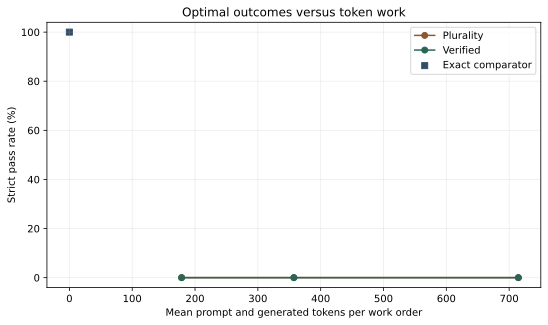

In [9]:
def row_scores(rows):
    return [int(row["strict_pass"]) for row in rows]


by_arm = {arm: [row for row in case_rows if row["arm"] == arm]
          for arm in dict.fromkeys(row["arm"] for row in case_rows)}
expected_ids = [order["case_id"] for order in work_orders]
for rows in by_arm.values():
    assert [row["case_id"] for row in rows] == expected_ids
greedy_rows = by_arm["greedy_1"]
greedy_correct = sum(row_scores(greedy_rows))
greedy_tokens = None if COURSE_SMOKE else sum(row["compute_proxy_tokens"] for row in greedy_rows)
scorecard = []
for arm, rows in by_arm.items():
    scores = row_scores(rows)
    correct = sum(scores)
    tokens = None if COURSE_SMOKE else sum(row["compute_proxy_tokens"] for row in rows)
    gained = sum(new > old for new, old in zip(scores, row_scores(greedy_rows)))
    lost = sum(new < old for new, old in zip(scores, row_scores(greedy_rows)))
    extra_tokens = tokens - greedy_tokens if tokens is not None and arm != "exact_reference" else None
    scorecard.append({
        "arm": arm,
        "cases": len(rows),
        "correct": correct,
        "strict_pass_rate": correct / len(rows),
        "outcomes": dict(Counter(row["outcome"] for row in rows)),
        "total_compute_proxy_tokens": tokens,
        "mean_compute_proxy_tokens": tokens / len(rows) if tokens is not None else None,
        "median_wall_ms": None if COURSE_SMOKE else median(row["comparison_wall_ms"] for row in rows),
        "gained_vs_greedy": gained,
        "lost_vs_greedy": lost,
        "extra_tokens_vs_greedy": extra_tokens,
        "tokens_per_added_win_vs_greedy": extra_tokens / (gained - lost)
        if extra_tokens is not None and gained > lost else None,
    })
by_slice = []
for category in SLICES:
    for arm, rows in by_arm.items():
        slice_rows = [row for row in rows if row["slice"] == category]
        by_slice.append({"slice": category, "arm": arm, "n": len(slice_rows),
                         "correct": sum(row_scores(slice_rows))})

generation_card = []
for samples in SAMPLE_COUNTS:
    rows = [row for row in generation_rows if row["samples"] == samples]
    assert [row["case_id"] for row in rows] == expected_ids
    peak_bytes = [row["peak_allocated_bytes"] for row in rows if row["peak_allocated_bytes"] is not None]
    extra_bytes = [row["peak_above_idle_bytes"] for row in rows if row["peak_above_idle_bytes"] is not None]
    generation_card.append({
        "samples": samples, "cases": len(rows),
        "with_feasible": sum(row["has_feasible"] for row in rows),
        "with_optimal": sum(row["has_optimal"] for row in rows),
        "median_distinct_parsed_pairs": median(row["distinct_parsed_pairs"] for row in rows),
        "median_generation_ms": None if COURSE_SMOKE else median(row["generation_wall_ms"] for row in rows),
        "peak_allocated_bytes": [min(peak_bytes), median(peak_bytes), max(peak_bytes)] if peak_bytes else None,
        "peak_above_idle_bytes": [min(extra_bytes), median(extra_bytes), max(extra_bytes)] if extra_bytes else None,
    })

comparisons = [(arm, "greedy_1") for arm in by_arm if arm != "greedy_1"]
comparisons += [(f"verified_{samples}", f"plurality_{samples}") for samples in SAMPLE_COUNTS if samples > 1]
intervals = []
for candidate_arm, incumbent_arm in comparisons:
    candidate_scores = row_scores(by_arm[candidate_arm])
    incumbent_scores = row_scores(by_arm[incumbent_arm])
    intervals.append({
        "candidate": candidate_arm, "incumbent": incumbent_arm,
        **paired_interval(work_orders, candidate_scores, incumbent_scores, draws=BOOTSTRAP_DRAWS),
        "gained": sum(new > old for new, old in zip(candidate_scores, incumbent_scores)),
        "lost": sum(new < old for new, old in zip(candidate_scores, incumbent_scores)),
    })
qualifying_arms = [
    row for row in scorecard if not COURSE_SMOKE and row["arm"] != "exact_reference"
    and row["strict_pass_rate"] >= MINIMUM_MODEL_PASS_RATE
]
candidate = min(qualifying_arms, key=lambda row: row["total_compute_proxy_tokens"], default=None)
configured_workload = {
    "cases": len(work_orders), "families": len(dev_assets), "slices": list(SLICES),
    "sample_counts": SAMPLE_COUNTS, "max_new_tokens": TOKEN_LIMIT,
    "temperature": SAMPLING_TEMPERATURE, "top_p": TOP_P, "bootstrap_draws": BOOTSTRAP_DRAWS,
    "model": MODEL_IDS["text"][0], "model_revision": MODEL_IDS["text"][1],
    "development_split": SPLIT_MANIFEST[ACTIVE_SPLIT],
}
results = {
    "mode": "constructed_fixtures" if COURSE_SMOKE else "development_model_comparison",
    "split": ACTIVE_SPLIT,
    "model_load_ms": load_ms,
    "lab_elapsed_ms": None if COURSE_SMOKE else (perf_counter() - run_started) * 1000,
    "workload": configured_workload,
    "model_quality_target": MINIMUM_MODEL_PASS_RATE,
    "budget_candidate": candidate,
    "scorecard": scorecard,
    "by_slice": by_slice,
    "candidate_batches": generation_card,
    "paired_intervals": intervals,
}
print("Development evidence:", json.dumps(results, default=_convert))
print("First and warm generation receipt:", first_and_warm)
opening_ids = set(expected_ids[:2])
print("Opening decisions:", [row for row in case_rows if row["case_id"] in opening_ids])
print("Opening proposals:", [row for row in generation_rows if row["case_id"] in opening_ids])
save("summary", results)
save("records", {
    "mode": results["mode"],
    "work_orders": work_orders, "policies": case_rows,
    "generations": generation_rows, "first_and_warm": first_and_warm,
})
if COURSE_SMOKE:
    chart("Strictly optimal work orders by policy", [row["arm"] for row in scorecard],
          [row["strict_pass_rate"] * 100 for row in scorecard], "Percent of work orders")
else:
    import matplotlib.pyplot as plt

    score_by_arm = {row["arm"]: row for row in scorecard}
    figure, axis = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
    for policy, color in (("plurality", "#8c5831"), ("verified", "#286556")):
        series = [score_by_arm["greedy_1"], score_by_arm[f"{policy}_2"], score_by_arm[f"{policy}_4"]]
        axis.plot(
            [row["mean_compute_proxy_tokens"] for row in series],
            [row["strict_pass_rate"] * 100 for row in series],
            marker="o", color=color, label=policy.capitalize(),
        )
    axis.scatter([0], [score_by_arm["exact_reference"]["strict_pass_rate"] * 100],
                 color="#334d68", marker="s", label="Exact comparator")
    axis.set(
        title="Optimal outcomes versus token work",
        xlabel="Mean prompt and generated tokens per work order",
        ylabel="Strict pass rate (%)",
        ylim=(-4, 104),
    )
    axis.grid(alpha=0.22)
    axis.legend(loc="best")
    figure.savefig(Path("evidence") / "quality-versus-compute.svg")
    plt.show()
    plt.close(figure)

Inspect cases where a larger sample set contains a good pair but voting
does not choose it. Separate failure to produce a feasible candidate
from failure to rank it. The exact comparator is tractable because the
input contains five candidates and only two can be chosen. Increasing
shortlist length, allowing several picks, or adding a harder constraint
changes that comparison. Keep those workloads separate from this result.

[Read the lesson and compare the measured results](https://docs.recohut.com/courses/advanced-ai-systems-engineering/1-measure-the-model/03-spend-inference-compute).

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [Scaling LLM Test-Time Compute Optimally can be More Effective than Scaling Model Parameters](https://arxiv.org/abs/2408.03314)